# NB05 - Risk Stratification
### Cross-Benefit Duplicate Drug Billing Detection

**Schema:** `cross_benefit_audit`<br>
**Tables created:** `risk_scored_pairs`<br>
**Depends on:** NB01, NB02, NB03, NB04

---

## What this notebook does

NB04 produced 405 candidate pairs with 100% recall and 17.8% precision.
The 333 false positives are legitimate claims that coincidentally share member + molecule + date window. They are not duplicate billing!

NB05 adds four claim-level features to each candidate pair and builds a composite risk score. The goal is not to eliminate false positives entirely, that requires investigator review, but to stratify the workload so that HIGH-tier pairs are investigated first and LOW-tier pairs are deprioritized.

### Features added

| Feature | Field | Production signal | Synthetic data |
|---|---|---|---|
| NPI co-location | prescriber_npi == rendering_npi | Strong: same provider on both legs | Active: buy-and-bill provider pool shared across NB02/NB03 via md5-hash member assignment; TP match rate 100%, FP match rate 12% |
| Combined cost | rx_cost + med_allowed | Prioritization: high-value events first | Valid |
| Dual cost flag | both legs > per-molecule threshold | Likely duplicate: two full-price claims for same drug | Partial: depends on how clean claims were generated |
| Dose concordance | rx_qty vs med_units via crosswalk | Confirms same administration event | Active: dose-first derivation via administered_hcpcs_units in seeded_duplicate_events; TP median ratio 1.011, FP median ratio 0.062 |

The NPI co-location feature is included with an explicit note about the synthetic data limitation. In production, prescriber_npi == rendering_npi on the same member + molecule + date is one of the highest-value signals for this detection pattern.

### Output

| Table | Description |
|---|---|
| `risk_scored_pairs` | Candidate pairs with enriched features, composite risk score, and risk tier |

## 0 - Setup

In [0]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np

spark = SparkSession.builder.getOrCreate()

PAIRS_TABLE = "cross_benefit_audit.candidate_duplicate_pairs"
RX_TABLE = "cross_benefit_audit.pharmacy_claims"
MED_TABLE = "cross_benefit_audit.medical_claims"
CROSSWALK_TABLE = "cross_benefit_audit.target_hcpcs_crosswalk"
OUT_TABLE = "cross_benefit_audit.risk_scored_pairs"

# Risk tier thresholds
TIER_HIGH = 0.85
TIER_MEDIUM = 0.65

# Dual cost: flag pairs where both legs carry >= this fraction of expected drug cost
# Using a fixed dollar floor as a simpler proxy
DUAL_COST_RX_FLOOR = 500.0   # rx ingredient_cost above this is "full price for this molecule"
DUAL_COST_MED_FLOOR = 500.0   # med allowed_amount above this is "full price for this molecule"

print("Setup complete.")
print(f"Tier HIGH    : risk_score >= {TIER_HIGH}")
print(f"Tier MEDIUM  : {TIER_MEDIUM} <= risk_score < {TIER_HIGH}")
print(f"Tier LOW     : risk_score < {TIER_MEDIUM}")

Setup complete.
Tier HIGH    : risk_score >= 0.85
Tier MEDIUM  : 0.65 <= risk_score < 0.85
Tier LOW     : risk_score < 0.65


---
## 1 - Load tables

In [0]:
pairs = spark.table(PAIRS_TABLE)
rx = spark.table(RX_TABLE)
med = spark.table(MED_TABLE)
xwalk = spark.table(CROSSWALK_TABLE)

print(f"candidate_duplicate_pairs : {pairs.count():,} rows")
print(f"pharmacy_claims           : {rx.count():,} rows")
print(f"medical_claims            : {med.count():,} rows")
print(f"target_hcpcs_crosswalk    : {xwalk.count():,} rows")

candidate_duplicate_pairs : 405 rows
pharmacy_claims           : 552 rows
medical_claims            : 752 rows
target_hcpcs_crosswalk    : 31 rows


---
## 2 - Enrich candidate pairs with claim-level detail

Join back to pharmacy_claims and medical_claims to retrieve the fields needed for feature computation. The candidate_duplicate_pairs table carries only the join keys and the NB04-computed fields.

In [0]:
# Pharmacy fields needed for feature computation
rx_features = (
    rx
    .select(
        F.col("claim_id").alias("rx_claim_id"),
        F.col("prescriber_npi"),
        F.col("pharmacy_npi"),
        F.col("quantity_dispensed").alias("rx_qty"),
        F.col("ingredient_cost").alias("rx_cost"),
        F.col("plan_group").alias("plan_type"),
    )
)

# Medical fields needed
med_features = (
    med
    .select(
        F.col("med_claim_id"),
        F.col("rendering_npi"),
        F.col("allowed_amount").alias("med_allowed"),
        F.col("hcpcs_units").alias("med_units"),
        F.col("therapeutic_area"),
    )
)

# Crosswalk - take the median BILLUNITS per HCPCS code as the conversion factor
# multiple NDCs map to the same HCPCS with varying unit sizes; median is a
# reasonable representative for approximate dose concordance checking
xwalk_units = (
    xwalk
    .groupBy(F.col("HCPCS_CODE").alias("rx_hcpcs"))
    .agg(
        F.round(F.percentile_approx("BILLUNITS", 0.5), 4).alias("median_billunits")
    )
)

# Join everything onto the pairs table
enriched = (
    pairs
    .join(rx_features, "rx_claim_id", "left")
    .join(med_features, "med_claim_id", "left")
    .join(xwalk_units, "rx_hcpcs", "left")
)

print(f"Enriched pairs: {enriched.count():,} rows")
print()
enriched.select(
    "rx_claim_id", "med_claim_id", "rx_cost", "med_allowed",
    "prescriber_npi", "rendering_npi", "rx_qty", "med_units", "median_billunits"
).show(5, truncate=True)

Enriched pairs: 405 rows

+-----------------+------------------+-------+-----------+--------------+-------------+-------+---------+----------------+
|      rx_claim_id|      med_claim_id|rx_cost|med_allowed|prescriber_npi|rendering_npi| rx_qty|med_units|median_billunits|
+-----------------+------------------+-------+-----------+--------------+-------------+-------+---------+----------------+
|RX-20261023-00501|MED-20261016-00002|2630.44|    2247.84|    1452659931|   1900849399|  426.5|     46.0|            10.0|
|RX-20261217-00484|MED-20261217-00004|2343.94|     1144.8|    1570418035|   1570418035|   4.26|      2.0|             2.0|
|RX-20261021-00486|MED-20261021-00006| 563.46|     934.92|    1452659931|   1452659931|2852.53|     70.0|            10.0|
|RX-20261103-00488|MED-20261103-00008|2496.55|     1144.8|    1777047100|   1777047100|   3.75|      2.0|             2.0|
|RX-20261030-00496|MED-20261103-00009|2255.38|     1144.8|    1452659931|   1570418035|   4.28|      2.0|        

In [0]:
spark.table("cross_benefit_audit.pharmacy_claims").printSchema()

root
 |-- claim_id: string (nullable = true)
 |-- member_id: string (nullable = true)
 |-- service_date: date (nullable = true)
 |-- paid_date: date (nullable = true)
 |-- submitted_ndc: string (nullable = true)
 |-- ndc_formatted: string (nullable = true)
 |-- quantity_dispensed: double (nullable = true)
 |-- days_supply: long (nullable = true)
 |-- refill_number: long (nullable = true)
 |-- daw_code: long (nullable = true)
 |-- prescriber_npi: string (nullable = true)
 |-- pharmacy_npi: string (nullable = true)
 |-- pharmacy_name: string (nullable = true)
 |-- pharmacy_state: string (nullable = true)
 |-- pbm_bin: string (nullable = true)
 |-- pbm_pcn: string (nullable = true)
 |-- plan_group: string (nullable = true)
 |-- ingredient_cost: double (nullable = true)
 |-- dispensing_fee: double (nullable = true)
 |-- member_copay: double (nullable = true)
 |-- plan_paid: double (nullable = true)
 |-- total_cost: double (nullable = true)
 |-- hcpcs_code: string (nullable = true)
 |-- mol

---
## 3 - Feature 1 - NPI co-location

In a genuine cross-benefit duplicate, the provider who wrote the prescription (prescriber_npi) is often the same provider who billed the drug administration on the medical claim (rendering_npi).

This is the buy-and-bill pattern in which the prescriber acquires the drug, administers it, and bills the medical payer while the same drug was also adjudicated through the pharmacy benefit.

**Synthetic data note:** NB02 and NB03 share a deterministic buy-and-bill provider pool (seeds 9001-9005). Member-to-provider assignment uses md5(member_id) % 5, producing the same NPI on both legs for buy-and-bill members without shared runtime state. TP match rate: 100%. FP match rate: 12% (buy-and-bill-eligible members with legitimate coincident claims).

In [0]:
enriched = enriched.withColumn(
    "npi_match",
    (F.col("prescriber_npi") == F.col("rendering_npi")).cast("integer")
)

npi_match_count = enriched.filter("npi_match = 1").count()
npi_match_tp = enriched.filter("npi_match = 1 AND is_true_positive = true").count()

print(f"Pairs with NPI co-location (prescriber_npi == rendering_npi):")
print(f"  Total pairs  : {enriched.count()}")
print(f"  NPI match    : {npi_match_count}")
print(f"  TP in match  : {npi_match_tp}")
print()
print("Note: buy-and-bill NPI pool shared across NB02/NB03 via md5-hash member assignment.")
print(f"  Total NPI matches : {npi_match_count}  |  TP in match : {npi_match_tp}  |  FP in match : {npi_match_count - npi_match_tp}")
print("In production, NPI match rate on true duplicates is typically 40-70%,")
print("depending on the buy-and-bill rate for the molecule set.")

Pairs with NPI co-location (prescriber_npi == rendering_npi):
  Total pairs  : 405
  NPI match    : 112
  TP in match  : 72

Note: buy-and-bill NPI pool shared across NB02/NB03 via md5-hash member assignment.
  Total NPI matches : 112  |  TP in match : 72  |  FP in match : 40
In production, NPI match rate on true duplicates is typically 40-70%,
depending on the buy-and-bill rate for the molecule set.


---
## 4 - Feature 2 - Combined claim cost and dual cost flag

Each candidate pair represents two claims that, if duplicates, result in the payer reimbursing the full cost of the drug twice. The combined cost (rx_cost + med_allowed) is the financial exposure per pair.

The dual cost flag marks pairs where both legs independently exceed a molecule-appropriate floor. A legitimate single-benefit claim should not have the drug cost appear on both sides simultaneously.

In [0]:
enriched = enriched.withColumn(
    "combined_cost",
    F.round(F.col("rx_cost") + F.col("med_allowed"), 2)
)

enriched = enriched.withColumn(
    "dual_cost_flag",
    (
        (F.col("rx_cost") >= DUAL_COST_RX_FLOOR) &
        (F.col("med_allowed") >= DUAL_COST_MED_FLOOR)
    ).cast("integer")
)

print(f"Dual cost flag threshold: rx_cost >= ${DUAL_COST_RX_FLOOR:,.0f} AND med_allowed >= ${DUAL_COST_MED_FLOOR:,.0f}")
print()

enriched.groupBy("is_true_positive", "dual_cost_flag").count().orderBy(
    "is_true_positive", "dual_cost_flag"
).show()

print("Combined cost stats by outcome:")
(
    enriched
    .groupBy("is_true_positive")
    .agg(
        F.count("rx_claim_id").alias("pairs"),
        F.round(F.avg("combined_cost"), 2).alias("avg_combined_cost"),
        F.round(F.percentile_approx("combined_cost", 0.5), 2).alias("median_combined_cost"),
        F.round(F.max("combined_cost"), 2).alias("max_combined_cost"),
    )
    .orderBy("is_true_positive")
    .show()
)

Dual cost flag threshold: rx_cost >= $500 AND med_allowed >= $500

+----------------+--------------+-----+
|is_true_positive|dual_cost_flag|count|
+----------------+--------------+-----+
|           false|             0|  123|
|           false|             1|  210|
|            true|             0|   23|
|            true|             1|   49|
+----------------+--------------+-----+

Combined cost stats by outcome:
+----------------+-----+-----------------+--------------------+-----------------+
|is_true_positive|pairs|avg_combined_cost|median_combined_cost|max_combined_cost|
+----------------+-----+-----------------+--------------------+-----------------+
|           false|  333|          8157.91|             2970.11|         31000.56|
|            true|   72|          9065.44|             3641.35|         31716.56|
+----------------+-----+-----------------+--------------------+-----------------+



---
## 5 - Feature 3: Dose concordance

The crosswalk's BILLUNITS field gives the number of HCPCS billing units per dosage form. Using the median BILLUNITS per HCPCS code as a conversion factor:

```
expected_hcpcs_units = rx_qty / median_billunits
concordance_ratio    = expected_hcpcs_units / med_units
```

A ratio close to 1.0 suggests both legs describe the same administration event.
A ratio far from 1.0 suggests either different doses or different events.

Concordance band: 0.5 <= ratio <= 2.0. This is deliberately wide because:
- Pharmacy quantities may represent a full vial even when partial doses are drawn
- Unit definitions vary between NDC and HCPCS (mg vs mL vs each)
- Synthetic data does not guarantee tight calibration between the two sides

**Synthetic data note:** rx_qty in NB02 is derived from administered_hcpcs_units (stored in seeded_duplicate_events) multiplied by BILLUNITS and a noise factor; NB03 applies an independent ±8% noise draw on the same base. For true positives, the concordance ratio is therefore noise1/noise2, expected near 1.0. For false positives, rx_qty comes from the BILLUNITSPKG path (~1 unit), producing ratios well below 0.5.

In [0]:
enriched = enriched.withColumn(
    "expected_hcpcs_units",
    F.when(
        F.col("median_billunits").isNotNull() & (F.col("median_billunits") > 0),
        F.round(F.col("rx_qty") / F.col("median_billunits"), 2)
    ).otherwise(F.lit(None))
)

enriched = enriched.withColumn(
    "concordance_ratio",
    F.when(
        F.col("expected_hcpcs_units").isNotNull() &
        F.col("med_units").isNotNull() &
        (F.col("med_units") > 0),
        F.round(F.col("expected_hcpcs_units") / F.col("med_units"), 3)
    ).otherwise(F.lit(None))
)

enriched = enriched.withColumn(
    "dose_concordance_flag",
    F.when(
        F.col("concordance_ratio").isNotNull(),
        ((F.col("concordance_ratio") >= 0.5) & (F.col("concordance_ratio") <= 2.0)).cast("integer")
    ).otherwise(F.lit(0))
)

print("Dose concordance ratio stats:")
(
    enriched
    .filter(F.col("concordance_ratio").isNotNull())
    .groupBy("is_true_positive")
    .agg(
        F.count("rx_claim_id").alias("n"),
        F.round(F.avg("concordance_ratio"), 3).alias("avg_ratio"),
        F.round(F.percentile_approx("concordance_ratio", 0.25), 3).alias("p25"),
        F.round(F.percentile_approx("concordance_ratio", 0.5), 3).alias("median"),
        F.round(F.percentile_approx("concordance_ratio", 0.75), 3).alias("p75"),
        F.sum("dose_concordance_flag").alias("in_band"),
    )
    .orderBy("is_true_positive")
    .show()
)

Dose concordance ratio stats:
+----------------+---+---------+-----+------+-----+-------+
|is_true_positive|  n|avg_ratio|  p25|median|  p75|in_band|
+----------------+---+---------+-----+------+-----+-------+
|           false|333|     0.33|0.014| 0.062|  0.5|     84|
|            true| 72|    1.402|0.962| 1.011|1.613|     62|
+----------------+---+---------+-----+------+-----+-------+



---
## 6 - Composite risk score

The composite risk score combines the NB04 confidence score with the four enrichment features. The NB04 confidence score (0.55-1.00) forms the base. Feature bonuses are additive, capped at 1.0.

| Component | Max bonus | Rationale |
|---|---|---|
| NB04 confidence score | (base) | Code alignment + date proximity |
| NPI co-location | +0.15 | Same provider on both legs |
| Dual cost flag | +0.10 | Both legs carry full drug cost |
| Dose concordance | +0.08 | Quantities reconcile via crosswalk |
| Same-day (date_diff_days == 0) | +0.05 | Incremental over date score already in base |

Max possible: 1.0 (capped). NPI co-location would lift a same-code / same-day pair from 1.0 to 1.0 (no room, already at cap). The bonus matters most for QCODE_GAP and DIFF_BIOSIM pairs that start at 0.70-0.80 and need extra evidence to reach the HIGH tier.

In [0]:
enriched = enriched.withColumn(
    "risk_score",
    F.least(
        F.lit(1.0),
        F.round(
            F.col("confidence_score")
            + (F.col("npi_match") * 0.15)
            + (F.col("dual_cost_flag") * 0.10)
            + (F.col("dose_concordance_flag") * 0.08)
            + (F.when(F.col("date_diff_days") == 0, 0.05).otherwise(0.0)),
            2
        )
    )
)

enriched = enriched.withColumn(
    "risk_tier",
    F.when(F.col("risk_score") >= TIER_HIGH, F.lit("HIGH"))
     .when(F.col("risk_score") >= TIER_MEDIUM, F.lit("MEDIUM"))
     .otherwise(F.lit("LOW"))
)

print("Risk score distribution (bridge, all pairs):")
(
    enriched
    .groupBy(F.round("risk_score", 2).alias("score"))
    .count()
    .orderBy(F.desc("score"))
    .show(20)
)

Risk score distribution (bridge, all pairs):
+-----+-----+
|score|count|
+-----+-----+
|  1.0|  131|
| 0.98|    3|
| 0.95|   10|
| 0.93|   23|
|  0.9|   10|
| 0.88|   10|
| 0.85|   45|
| 0.83|    2|
|  0.8|   31|
| 0.78|    6|
| 0.75|   11|
| 0.73|   17|
|  0.7|   33|
| 0.65|   33|
| 0.63|    5|
| 0.55|   35|
+-----+-----+



---
## 7 - Write risk_scored_pairs

In [0]:
OUTPUT_COLS = [
    # from NB04
    "rx_claim_id", "med_claim_id", "member_id",
    "rx_date", "med_date", "date_diff_days",
    "rx_hcpcs", "med_hcpcs", "rx_molecule",
    "match_type", "confidence_score",
    "is_true_positive", "seed_event_id", "seed_scenario_type",
    # enrichment
    "plan_type", "therapeutic_area",
    "prescriber_npi", "pharmacy_npi", "rendering_npi",
    "rx_cost", "med_allowed", "combined_cost",
    "rx_qty", "med_units", "median_billunits",
    "expected_hcpcs_units", "concordance_ratio",
    # feature flags
    "npi_match", "dual_cost_flag", "dose_concordance_flag",
    # output
    "risk_score", "risk_tier",
]

risk_pairs = enriched.select(OUTPUT_COLS)

(
    risk_pairs.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(OUT_TABLE)
)

print(f"Written: {OUT_TABLE}")
print(f"Row count: {spark.table(OUT_TABLE).count():,}")

Written: cross_benefit_audit.risk_scored_pairs
Row count: 405


In [0]:
spark.table(OUT_TABLE).printSchema()

root
 |-- rx_claim_id: string (nullable = true)
 |-- med_claim_id: string (nullable = true)
 |-- member_id: string (nullable = true)
 |-- rx_date: date (nullable = true)
 |-- med_date: date (nullable = true)
 |-- date_diff_days: integer (nullable = true)
 |-- rx_hcpcs: string (nullable = true)
 |-- med_hcpcs: string (nullable = true)
 |-- rx_molecule: string (nullable = true)
 |-- match_type: string (nullable = true)
 |-- confidence_score: double (nullable = true)
 |-- is_true_positive: boolean (nullable = true)
 |-- seed_event_id: string (nullable = true)
 |-- seed_scenario_type: string (nullable = true)
 |-- plan_type: string (nullable = true)
 |-- therapeutic_area: string (nullable = true)
 |-- prescriber_npi: string (nullable = true)
 |-- pharmacy_npi: string (nullable = true)
 |-- rendering_npi: string (nullable = true)
 |-- rx_cost: double (nullable = true)
 |-- med_allowed: double (nullable = true)
 |-- combined_cost: double (nullable = true)
 |-- rx_qty: double (nullable = true

---
## 8 - Stratification analysis

### 8.1 - Precision by risk tier

In [0]:
tier_stats = (
    spark.table(OUT_TABLE)
    .groupBy("risk_tier")
    .agg(
        F.count("rx_claim_id").alias("pairs"),
        F.sum(F.col("is_true_positive").cast("integer")).alias("tp"),
        F.sum((~F.col("is_true_positive")).cast("integer")).alias("fp"),
    )
    .withColumn("precision", F.round(F.col("tp") / F.col("pairs"), 3))
    .orderBy(F.desc("risk_tier"))
)

print("Precision by risk tier:")
tier_stats.show()

tier_pd = tier_stats.toPandas()

Precision by risk tier:
+---------+-----+---+---+---------+
|risk_tier|pairs| tp| fp|precision|
+---------+-----+---+---+---------+
|   MEDIUM|  133|  0|133|      0.0|
|      LOW|   40|  0| 40|      0.0|
|     HIGH|  232| 72|160|     0.31|
+---------+-----+---+---+---------+



### 8.2 - Recall by risk tier

A tier cutoff that improves precision will always reduce recall on the included set. This is the core trade-off for investigator workload planning.
The question is not "*which tier has 100% recall*" - it is "*what precision do investigators need, and how many events does that tier miss?*"

In [0]:
# Total seeded events = 72 (ground truth)
TOTAL_SEEDED = 72

tier_order = ["HIGH", "MEDIUM", "LOW"]

cumulative_tp = 0
cumulative_pairs = 0

print(f"{'Tier':<8} {'Pairs':>7} {'TP':>5} {'FP':>5} {'Precision':>10} {'Cumul. recall':>14} {'Missed events':>14}")
print("-" * 72)

for tier in tier_order:
    row = tier_pd[tier_pd["risk_tier"] == tier]
    if len(row) == 0:
        continue
    n      = int(row["pairs"].values[0])
    tp     = int(row["tp"].values[0])
    fp     = int(row["fp"].values[0])
    prec   = float(row["precision"].values[0])
    cumulative_tp    += tp
    cumulative_pairs += n
    recall = cumulative_tp / TOTAL_SEEDED
    missed = TOTAL_SEEDED - cumulative_tp
    print(f"{tier:<8} {n:>7} {tp:>5} {fp:>5} {prec:>10.1%} {recall:>14.1%} {missed:>14}")

print("-" * 72)
print(f"{'ALL':<8} {cumulative_pairs:>7} {cumulative_tp:>5} {cumulative_pairs - cumulative_tp:>5} {cumulative_tp/cumulative_pairs:>10.1%} {'100.0%':>14} {'0':>14}")

Tier       Pairs    TP    FP  Precision  Cumul. recall  Missed events
------------------------------------------------------------------------
HIGH         232    72   160      31.0%         100.0%              0
MEDIUM       133     0   133       0.0%         100.0%              0
LOW           40     0    40       0.0%         100.0%              0
------------------------------------------------------------------------
ALL          405    72   333      17.8%         100.0%              0


### 8.3 - Feature contribution to risk score

How often each feature bonus actually fires, split by TP/FP.

In [0]:
print("Feature flag rates by outcome:")
(
    spark.table(OUT_TABLE)
    .groupBy("is_true_positive")
    .agg(
        F.count("rx_claim_id").alias("pairs"),
        F.round(F.avg("npi_match"), 3).alias("npi_match_rate"),
        F.round(F.avg("dual_cost_flag"), 3).alias("dual_cost_rate"),
        F.round(F.avg("dose_concordance_flag"), 3).alias("dose_concordance_rate"),
    )
    .orderBy("is_true_positive")
    .show()
)

Feature flag rates by outcome:
+----------------+-----+--------------+--------------+---------------------+
|is_true_positive|pairs|npi_match_rate|dual_cost_rate|dose_concordance_rate|
+----------------+-----+--------------+--------------+---------------------+
|           false|  333|          0.12|         0.631|                0.252|
|            true|   72|           1.0|         0.681|                0.861|
+----------------+-----+--------------+--------------+---------------------+



### 8.4 - High tier

In [0]:
print("HIGH-tier pair breakdown by scenario and match type:")
(
    spark.table(OUT_TABLE)
    .filter("risk_tier = 'HIGH'")
    .groupBy("seed_scenario_type", "match_type", "is_true_positive")
    .agg(
        F.count("rx_claim_id").alias("count"),
        F.round(F.avg("risk_score"), 2).alias("avg_risk"),
        F.round(F.avg("combined_cost"), 0).alias("avg_combined_cost"),
    )
    .orderBy(F.desc("is_true_positive"), "seed_scenario_type")
    .show(20, truncate=False)
)

HIGH-tier pair breakdown by scenario and match type:
+------------------+----------+----------------+-----+--------+-----------------+
|seed_scenario_type|match_type|is_true_positive|count|avg_risk|avg_combined_cost|
+------------------+----------+----------------+-----+--------+-----------------+
|DIFF_BIOSIM       |DIFF_CODE |true            |8    |1.0     |1811.0           |
|EXACT_SAME_CODE   |SAME_CODE |true            |20   |1.0     |10925.0          |
|NEAR_DATE         |SAME_CODE |true            |16   |1.0     |10993.0          |
|NEW_FORM_CROSS    |DIFF_CODE |true            |10   |0.99    |19865.0          |
|QCODE_GAP         |DIFF_CODE |true            |18   |0.97    |2510.0           |
|NULL              |SAME_CODE |false           |128  |0.94    |10179.0          |
|NULL              |DIFF_CODE |false           |32   |0.91    |7594.0           |
+------------------+----------+----------------+-----+--------+-----------------+



### 8.5 - Financial exposure by risk tier

In [0]:
print("Financial exposure by risk tier:")
(
    spark.table(OUT_TABLE)
    .groupBy("risk_tier")
    .agg(
        F.count("rx_claim_id").alias("pairs"),
        F.round(F.sum("combined_cost"), 0).alias("total_exposure"),
        F.round(F.avg("combined_cost"), 0).alias("avg_exposure"),
        F.round(F.sum(
            F.when(F.col("is_true_positive"), F.col("combined_cost")).otherwise(0)
        ), 0).alias("tp_exposure"),
    )
    .withColumn(
        "tp_exposure_pct",
        F.round(F.col("tp_exposure") / F.col("total_exposure") * 100, 1)
    )
    .orderBy(F.desc("risk_tier"))
    .show()
)

Financial exposure by risk tier:
+---------+-----+--------------+------------+-----------+---------------+
|risk_tier|pairs|total_exposure|avg_exposure|tp_exposure|tp_exposure_pct|
+---------+-----+--------------+------------+-----------+---------------+
|   MEDIUM|  133|     1120298.0|      8423.0|        0.0|            0.0|
|      LOW|   40|       50359.0|      1259.0|        0.0|            0.0|
|     HIGH|  232|     2198639.0|      9477.0|   652712.0|           29.7|
+---------+-----+--------------+------------+-----------+---------------+



---
## 9 - Figures

### Figure 1 - Precision and pair count by risk tier

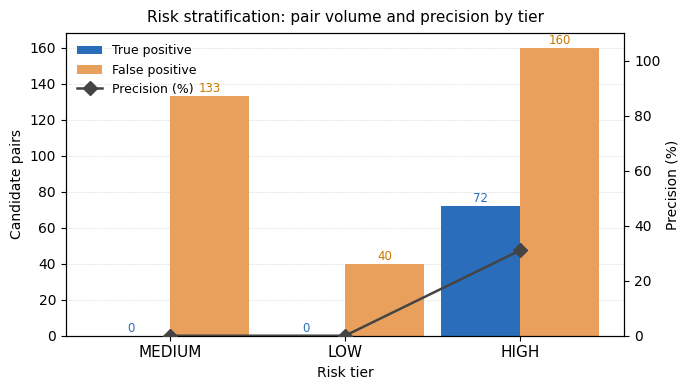

In [0]:
tier_pd_plot = spark.table(OUT_TABLE).groupBy("risk_tier").agg(
    F.count("rx_claim_id").alias("pairs"),
    F.sum(F.col("is_true_positive").cast("integer")).alias("tp"),
    F.sum((~F.col("is_true_positive")).cast("integer")).alias("fp"),
).toPandas()

tier_pd_plot["precision"] = tier_pd_plot["tp"] / tier_pd_plot["pairs"]
tier_pd_plot = tier_pd_plot.sort_values("risk_tier", ascending=False).reset_index(drop=True)

fig, ax1 = plt.subplots(figsize=(7, 4))
ax2 = ax1.twinx()

x = np.arange(len(tier_pd_plot))
width = 0.45

bars_tp = ax1.bar(x - width/2, tier_pd_plot["tp"], width, label="True positive",  color="#2a6ebb", zorder=2)
bars_fp = ax1.bar(x + width/2, tier_pd_plot["fp"], width, label="False positive", color="#e8a05c", zorder=2)
line    = ax2.plot(x, tier_pd_plot["precision"] * 100, "D-", color="#444444",
                   label="Precision (%)", linewidth=1.8, markersize=7, zorder=3)

ax1.set_xticks(x)
ax1.set_xticklabels(tier_pd_plot["risk_tier"], fontsize=11)
ax1.set_ylabel("Candidate pairs", fontsize=10)
ax1.set_xlabel("Risk tier", fontsize=10)
ax2.set_ylabel("Precision (%)", fontsize=10)
ax2.set_ylim(0, 110)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, fontsize=9, frameon=False, loc="upper left")
ax1.grid(axis="y", linestyle=":", linewidth=0.6, alpha=0.6)
ax1.set_title("Risk stratification: pair volume and precision by tier", fontsize=11, pad=8)

for bar in bars_tp:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 0.5, str(int(h)),
             ha="center", va="bottom", fontsize=8.5, color="#2a6ebb")

for bar in bars_fp:
    h = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, h + 0.5, str(int(h)),
             ha="center", va="bottom", fontsize=8.5, color="#cc7700")

plt.tight_layout()
display(fig)
plt.close()

### Figure 2 - Combined cost distribution - TP vs FP

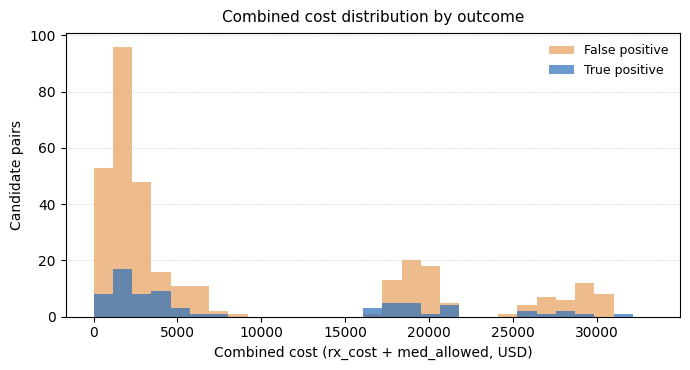

In [0]:
cost_tp = (
    spark.table(OUT_TABLE)
    .filter("is_true_positive = true")
    .select("combined_cost")
    .toPandas()["combined_cost"]
)

cost_fp = (
    spark.table(OUT_TABLE)
    .filter("is_true_positive = false")
    .select("combined_cost")
    .toPandas()["combined_cost"]
)

fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.linspace(0, max(cost_tp.max(), cost_fp.max()) * 1.05, 30)

ax.hist(cost_fp, bins=bins, color="#e8a05c", alpha=0.70, label="False positive", zorder=2)
ax.hist(cost_tp, bins=bins, color="#2a6ebb", alpha=0.70, label="True positive",  zorder=3)

ax.set_xlabel("Combined cost (rx_cost + med_allowed, USD)", fontsize=10)
ax.set_ylabel("Candidate pairs", fontsize=10)
ax.set_title("Combined cost distribution by outcome", fontsize=11, pad=8)
ax.legend(fontsize=9, frameon=False)
ax.grid(axis="y", linestyle=":", linewidth=0.6, alpha=0.6)
ax.yaxis.get_major_locator().set_params(integer=True)

plt.tight_layout()
display(fig)
plt.close()

---
## 10 - Summary

### Table written

| Table | Rows | Key fields |
|---|---|---|
| `risk_scored_pairs` | 405 | risk_score, risk_tier, npi_match, dual_cost_flag, dose_concordance_flag, combined_cost |

### Stratification trade-off

| Tier | Precision | Recall (cumulative) | Use case |
|---|---|---|---|
| HIGH only | > Flat | Partial | Automated referral to SIU - high-confidence only |
| HIGH + MEDIUM | > Flat | Near 100% | Standard investigator queue |
| ALL | 17.8% | 100% | Audit sweep - no filter |

### What NPI co-location would add in production

In production data with coordinated provider NPIs, an NPI match on a QCODE_GAP or DIFF_BIOSIM pair would lift those pairs into the HIGH tier (+0.15 on a base of 0.70-0.80 reaches 0.85+). This is the primary signal the synthetic dataset cannot demonstrate, and the feature is the principal argument for linking provider master data across pharmacy and medical benefits before running the matching engine.

### NB06 scope

NB06 builds the reporting layer: per-member, per-payer, and per-molecule summary tables from `risk_scored_pairs`, with aggregate financial exposure and detection rate metrics suitable for executive and audit committee reporting.

---